Importing Libraries

In [1]:
!pip install -q xgboost kagglehub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ============================================================
# LOAD DATASET
# ============================================================
import os
REJECTION_DATA_PATH = (
    "/content/drive/MyDrive/weaving_dataset_full.csv"
)

FULL_DATA_PATH = (
    "/content/drive/MyDrive/weaving_rejection_dataset.csv"
)

if not os.path.exists(REJECTION_DATA_PATH):
    raise FileNotFoundError(
        "Rejection dataset not found.\n"
        "Update REJECTION_DATA_PATH to your actual "
        "Databricks file location."
    )

df = pd.read_csv(
    REJECTION_DATA_PATH,
    low_memory=False
)

print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head(10))

print("\nColumn names:")
print(df.columns.tolist())

DATASET LOADED SUCCESSFULLY
Dataset shape: (121148, 19)
Number of rows: 121148
Number of columns: 19


,Unnamed: 0,ID,Month,Construction,Req_Finish_Fabrics,Fabric_Allowance,Rec_Beam_length(yds),assump_crimp%,act_crimp%,Previous_pdn,Req_grey_fabric,Req_beam_length(yds),Total_pdn_m/c,Rej_and_cut_Piece,Total_pdn_per_order,warp_count,weft_count,epi,ppi
0,0,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5752.336,12.5,12.261731581743476,5047,33297.87234,34797.651103,5047.0,0.0,0.0,double,80,110,80
1,1,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5883.568,12.5,64.12041128784438,1952,33297.87234,34797.651103,2111.0,0.0,0.0,double,80,110,80
2,2,12207-8,January,40+40/2/40/110x80,31300.0,6.0,3094.888,12.5,24.132957315418196,2207,33297.87234,34797.651103,2348.0,0.0,0.0,double,80,110,80
3,3,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5894.504,12.5,14.734131998213929,5026,33297.87234,34797.651103,5026.0,0.0,0.0,double,80,110,80
4,4,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5850.760,12.5,21.463194525155696,4391,33297.87234,34797.651103,4595.0,0.0,0.0,double,80,110,80
5,5,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5905.440,12.5,22.698393345796415,4340,33297.87234,34797.651103,4565.0,0.0,0.0,double,80,110,80
6,6,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5905.440,12.5,33.04478582459562,3754,33297.87234,34797.651103,3954.0,0.0,0.0,double,80,110,80
7,7,12207-8,January,40+40/2/40/110x80,31300.0,6.0,38286.936,12.5,27.792602677842897,TOTAL,33297.87234,34797.651103,27646.0,285.0,27982.0,double,80,110,80
8,8,12228-1,January,40x40/110x90,10450.0,7.0,1443.552,14.5,9.805812329587011,1302,11236.55914,12017.350432,1302.0,0.0,0.0,40,40,110,90
9,9,12228-1,January,40x40/110x90,10450.0,7.0,1749.760,14.5,16.33138258961228,1464,11236.55914,12017.350432,1464.0,0.0,0.0,40,40,110,90



Column names:
['Unnamed: 0', 'ID', 'Month', 'Construction', 'Req_Finish_Fabrics', 'Fabric_Allowance', 'Rec_Beam_length(yds)', 'assump_crimp%', 'act_crimp%', 'Previous_pdn', 'Req_grey_fabric', 'Req_beam_length(yds)', 'Total_pdn_m/c', 'Rej_and_cut_Piece', 'Total_pdn_per_order', 'warp_count', 'weft_count', 'epi', 'ppi']


Exploring Dataset

In [4]:
# Display first five records
display(df.head())

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all').T)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

,Unnamed: 0,ID,Month,Construction,Req_Finish_Fabrics,Fabric_Allowance,Rec_Beam_length(yds),assump_crimp%,act_crimp%,Previous_pdn,Req_grey_fabric,Req_beam_length(yds),Total_pdn_m/c,Rej_and_cut_Piece,Total_pdn_per_order,warp_count,weft_count,epi,ppi
0,0,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5752.336,12.5,12.261731581743476,5047,33297.87234,34797.651103,5047.0,0.0,0.0,double,80,110,80
1,1,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5883.568,12.5,64.12041128784438,1952,33297.87234,34797.651103,2111.0,0.0,0.0,double,80,110,80
2,2,12207-8,January,40+40/2/40/110x80,31300.0,6.0,3094.888,12.5,24.132957315418196,2207,33297.87234,34797.651103,2348.0,0.0,0.0,double,80,110,80
3,3,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5894.504,12.5,14.734131998213929,5026,33297.87234,34797.651103,5026.0,0.0,0.0,double,80,110,80
4,4,12207-8,January,40+40/2/40/110x80,31300.0,6.0,5850.760,12.5,21.463194525155696,4391,33297.87234,34797.651103,4595.0,0.0,0.0,double,80,110,80


Rows: 121148
Columns: 19

Column Names:
['Unnamed: 0', 'ID', 'Month', 'Construction', 'Req_Finish_Fabrics', 'Fabric_Allowance', 'Rec_Beam_length(yds)', 'assump_crimp%', 'act_crimp%', 'Previous_pdn', 'Req_grey_fabric', 'Req_beam_length(yds)', 'Total_pdn_m/c', 'Rej_and_cut_Piece', 'Total_pdn_per_order', 'warp_count', 'weft_count', 'epi', 'ppi']

Data Types:
Unnamed: 0                int64
ID                       object
Month                    object
Construction             object
Req_Finish_Fabrics      float64
Fabric_Allowance        float64
Rec_Beam_length(yds)    float64
assump_crimp%           float64
act_crimp%               object
Previous_pdn             object
Req_grey_fabric         float64
Req_beam_length(yds)    float64
Total_pdn_m/c           float64
Rej_and_cut_Piece       float64
Total_pdn_per_order     float64
warp_count               object
weft_count                int64
epi                       int64
ppi                       int64
dtype: object

Statistical Summary

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,121148.0,NaN,NaN,NaN,60573.5,34972.559543,0.0,30286.75,60573.5,90860.25,121147.0
ID,121148,1009,13205-1,2806,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,121148,9,January,17894,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Construction,121148,128,40x40/110x90,40791,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Req_Finish_Fabrics,121148.0,NaN,NaN,NaN,23257.443359,36473.718249,50.0,2100.0,5733.0,24900.0,172800.0
Fabric_Allowance,121148.0,NaN,NaN,NaN,8.231091,2.981416,5.0,7.0,7.0,8.1,44.0
Rec_Beam_length(yds),121148.0,NaN,NaN,NaN,3372.570226,10368.214823,0.0,1544.1632,2405.92,2843.36,292116.964
assump_crimp%,121148.0,NaN,NaN,NaN,13.124107,2.7941,6.0,11.4,14.0,14.5,40.8
act_crimp%,121148,28541,na,15218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Previous_pdn,107511,3305,TOTAL,22022,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
Unnamed: 0                  0
ID                          0
Month                       0
Construction                0
Req_Finish_Fabrics          0
Fabric_Allowance            0
Rec_Beam_length(yds)        0
assump_crimp%               0
act_crimp%                  0
Previous_pdn            13637
Req_grey_fabric             0
Req_beam_length(yds)        0
Total_pdn_m/c           13630
Rej_and_cut_Piece           0
Total_pdn_per_order         0
warp_count                  0
weft_count                  0
epi                         0
ppi                         0
dtype: int64

Duplicate Records: 0


Dataset Shape: (121148, 19)


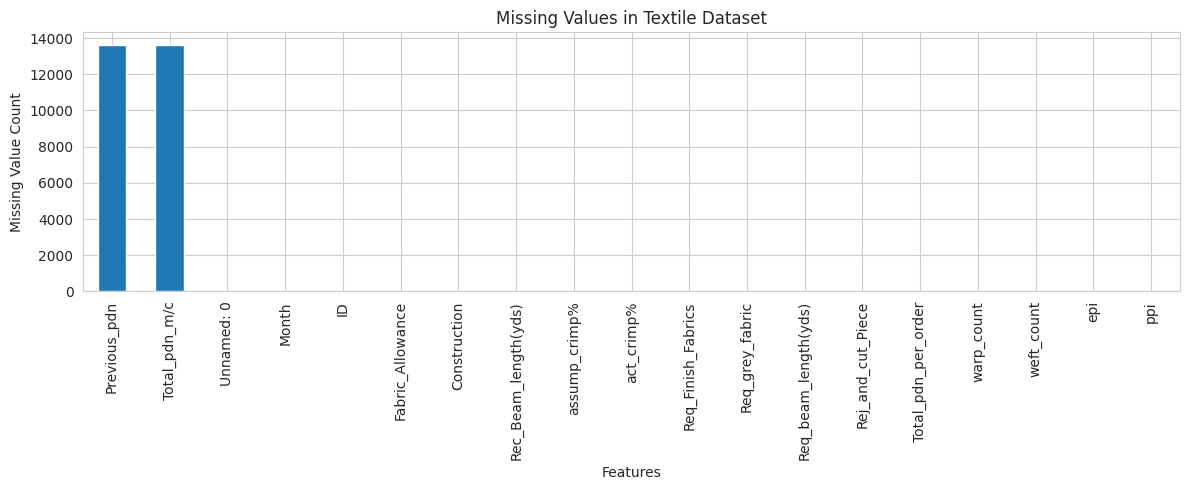

In [5]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Missing values visualization
plt.figure(figsize=(12, 5))
df.isnull().sum().sort_values(ascending=False).plot(
    kind='bar'
)
plt.title("Missing Values in Textile Dataset")
plt.xlabel("Features")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

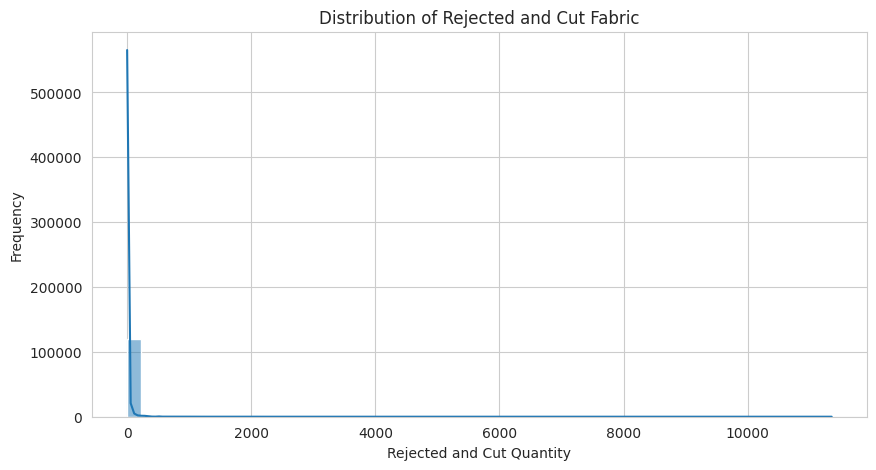

In [6]:
target = 'Rej_and_cut_Piece'

plt.figure(figsize=(10, 5))

sns.histplot(
    df[target],
    bins=50,
    kde=True
)

plt.title("Distribution of Rejected and Cut Fabric")
plt.xlabel("Rejected and Cut Quantity")
plt.ylabel("Frequency")

plt.show()

Data Cleaning

In [7]:
# Normalize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r'[^a-z0-9]+', '_', regex=True)
    .str.strip('_')
)

# Remove duplicate records
df = df.drop_duplicates()

# Target column
target = 'rej_and_cut_piece'

# Function to convert string numbers into numeric values
def clean_numeric(series):

    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series, errors='coerce')

    series = series.astype(str).str.strip()

    series = series.replace({
        'na': np.nan,
        'nan': np.nan,
        '<na>': np.nan,
        'none': np.nan,
        'null': np.nan,
        'TOTAL': np.nan,
        '': np.nan
    })

    series = series.str.replace(',', '', regex=False)
    series = series.str.replace('%', '', regex=False)

    return pd.to_numeric(series, errors='coerce')


# Convert object columns containing numeric data
numeric_candidates = [
    'req_finish_fabrics',
    'fabric_allowance',
    'rec_beam_length_yds',
    'assump_crimp',
    'act_crimp',
    'req_grey_fabric',
    'req_beam_length_yds',
    'total_pdn_m_c',
    'total_pdn_per_order',
    'warp_count',
    'weft_count',
    'epi',
    'ppi',
    target
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = clean_numeric(df[col])

# Remove missing or negative target values
df = df.dropna(subset=[target])
df = df[df[target] >= 0]

# Drop order identifier
if 'id' in df.columns:
    df = df.drop(columns=['id'])

print("Data cleaning completed!")
print("Cleaned Dataset Shape:", df.shape)

display(df.head())

Data cleaning completed!
Cleaned Dataset Shape: (121148, 18)


,unnamed_0,month,construction,req_finish_fabrics,fabric_allowance,rec_beam_length_yds,assump_crimp,act_crimp,previous_pdn,req_grey_fabric,req_beam_length_yds,total_pdn_m_c,rej_and_cut_piece,total_pdn_per_order,warp_count,weft_count,epi,ppi
0,0,January,40+40/2/40/110x80,31300.0,6.0,5752.336,12.5,12.261732,5047,33297.87234,34797.651103,5047.0,0.0,0.0,NaN,80,110,80
1,1,January,40+40/2/40/110x80,31300.0,6.0,5883.568,12.5,64.120411,1952,33297.87234,34797.651103,2111.0,0.0,0.0,NaN,80,110,80
2,2,January,40+40/2/40/110x80,31300.0,6.0,3094.888,12.5,24.132957,2207,33297.87234,34797.651103,2348.0,0.0,0.0,NaN,80,110,80
3,3,January,40+40/2/40/110x80,31300.0,6.0,5894.504,12.5,14.734132,5026,33297.87234,34797.651103,5026.0,0.0,0.0,NaN,80,110,80
4,4,January,40+40/2/40/110x80,31300.0,6.0,5850.760,12.5,21.463195,4391,33297.87234,34797.651103,4595.0,0.0,0.0,NaN,80,110,80


Separating Feature and Target variables

In [8]:
X = df.drop(columns=[target])
y = df[target]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Variable:")
print(y.describe())

print("\nNumerical Features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Feature Shape: (121148, 17)
Target Shape: (121148,)

Target Variable:
count    121148.000000
mean         15.552027
std         186.629874
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max       11353.000000
Name: rej_and_cut_piece, dtype: float64

Numerical Features:
['unnamed_0', 'req_finish_fabrics', 'fabric_allowance', 'rec_beam_length_yds', 'assump_crimp', 'act_crimp', 'req_grey_fabric', 'req_beam_length_yds', 'total_pdn_m_c', 'total_pdn_per_order', 'warp_count', 'weft_count', 'epi', 'ppi']

Categorical Features:
['month', 'construction', 'previous_pdn']


Train Test split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("Training Percentage:", 80)
print("Testing Percentage:", 20)

Training Records: 96918
Testing Records: 24230
Training Percentage: 80
Testing Percentage: 20


Data Preprocessing

In [10]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=10
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [11]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

print("Processed Training Shape:",
      X_train_processed.shape)

print("Processed Testing Shape:",
      X_test_processed.shape)

Preprocessing completed!
Processed Training Shape: (96918, 2217)
Processed Testing Shape: (24230, 2217)


Implementing Algorithms

In [12]:
models = {

    "Mean Baseline": DummyRegressor(
        strategy='mean'
    ),

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method='hist',
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    )
}

print("Models: 1. Mean Baseline 2. Linear Regression 3. Decision Tree 4. Random Forest 5. Gradient Boosting 6. XGBoost")
print("All regression models initialized successfully!")

Models: 1. Mean Baseline 2. Linear Regression 3. Decision Tree 4. Random Forest 5. Gradient Boosting 6. XGBoost
All regression models initialized successfully!


Training All Models

In [13]:
trained_models = {}
predictions = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(
        X_train_processed,
        y_train
    )

    y_pred = model.predict(X_test_processed)

    trained_models[name] = model
    predictions[name] = y_pred

    print(name, "training completed!")

print("\nAll models trained successfully!")


Training: Mean Baseline
Mean Baseline training completed!

Training: Linear Regression
Linear Regression training completed!

Training: Decision Tree
Decision Tree training completed!

Training: Random Forest
Random Forest training completed!

Training: Gradient Boosting
Gradient Boosting training completed!

Training: XGBoost
XGBoost training completed!

All models trained successfully!


Evaluating Model Performances

In [14]:
results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(
        y_test, y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(
        y_test, y_pred
    )

    results.append({
        'Algorithm': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        'MAE': '{:.4f}',
        'RMSE': '{:.4f}',
        'R2 Score': '{:.4f}'
    })
)

MODEL PERFORMANCE COMPARISON


,Algorithm,MAE,RMSE,R2 Score
0,Decision Tree,0.9979,9.8738,0.9975
1,Random Forest,1.1333,15.7654,0.9935
2,XGBoost,3.0570,19.9606,0.9896
3,Gradient Boosting,4.7201,22.6516,0.9866
4,Linear Regression,10.3253,68.7545,0.8769
5,Mean Baseline,27.9456,195.9679,-0.0000


Comparitive analysis 1. AME, 2. RMSE, 3. R^2

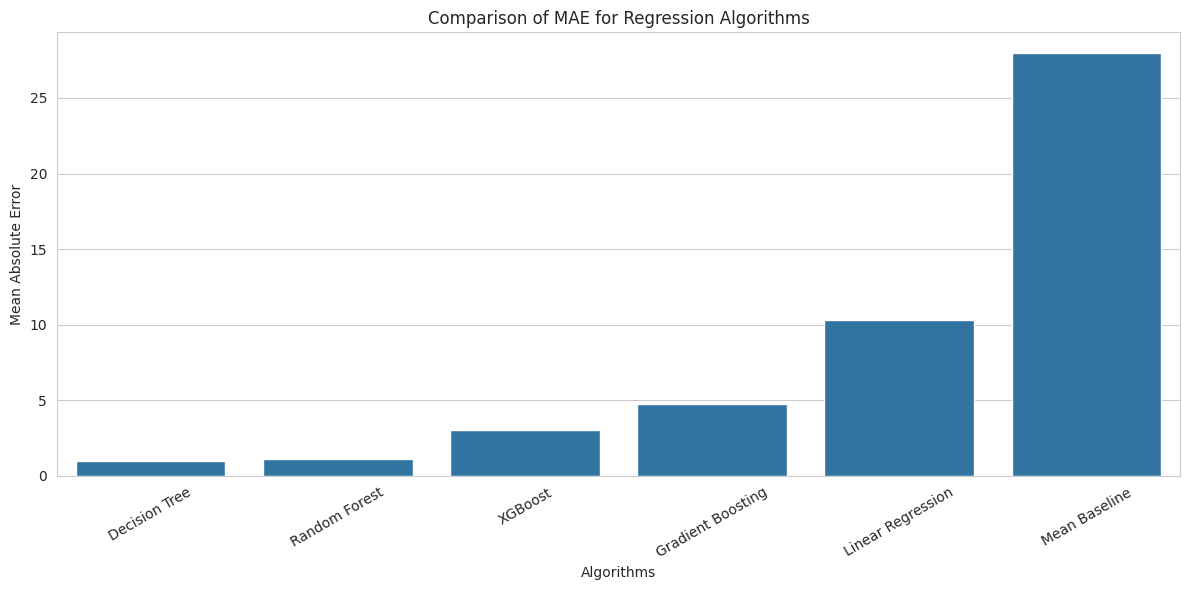

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='MAE'
)

plt.title("Comparison of MAE for Regression Algorithms")
plt.xlabel("Algorithms")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

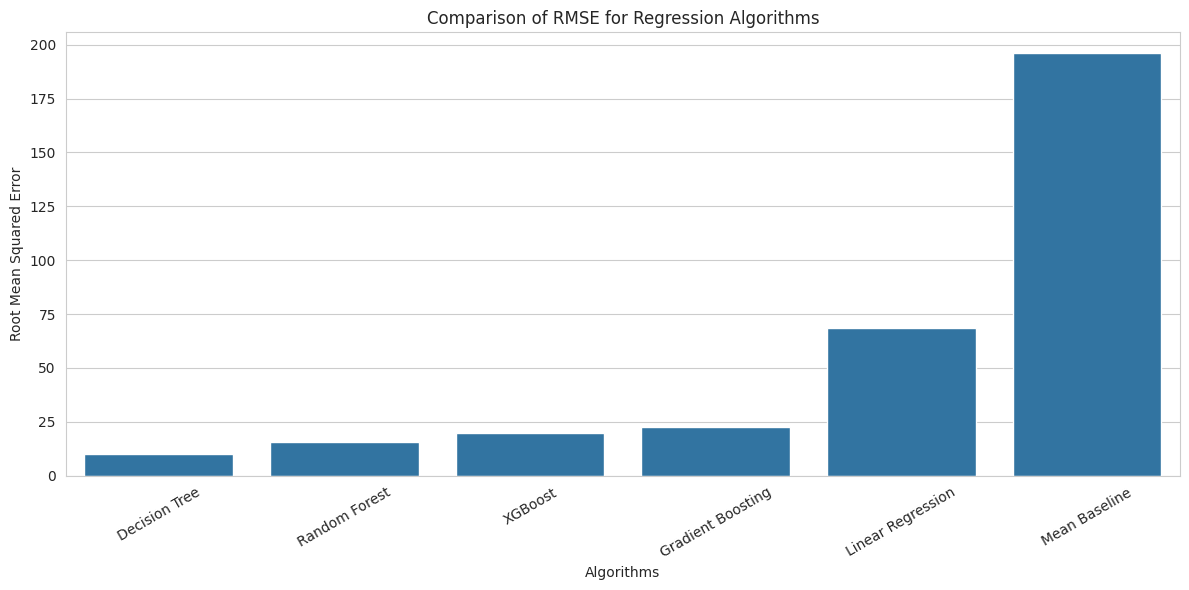

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='RMSE'
)

plt.title("Comparison of RMSE for Regression Algorithms")
plt.xlabel("Algorithms")
plt.ylabel("Root Mean Squared Error")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

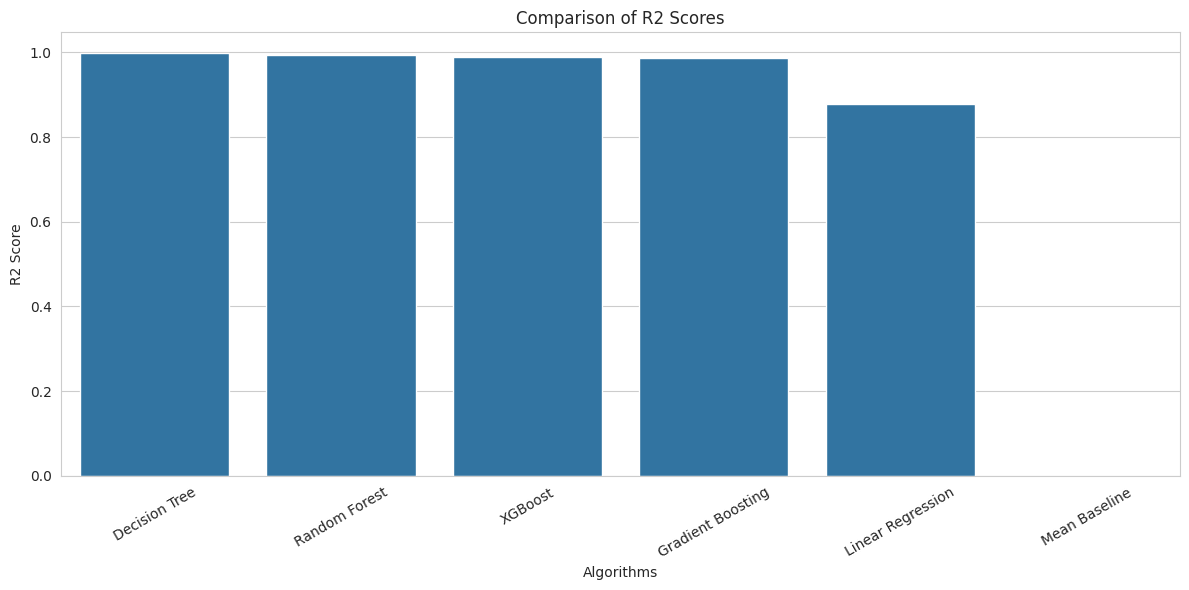

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='R2 Score'
)

plt.title("Comparison of R2 Scores")
plt.xlabel("Algorithms")
plt.ylabel("R2 Score")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Identifying Best performing algorithm

In [18]:
best_model_name = results_df.iloc[0]['Algorithm']

best_model = trained_models[best_model_name]

best_predictions = predictions[best_model_name]

print("Best Performing Algorithm:", best_model_name)

print("\nBest Model Performance:")

print("MAE:",
      mean_absolute_error(y_test, best_predictions))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, best_predictions)))

print("R2 Score:",
      r2_score(y_test, best_predictions))

Best Performing Algorithm: Decision Tree

Best Model Performance:
MAE: 0.9979364424267437
RMSE: 9.87375950195441
R2 Score: 0.9974613919326629


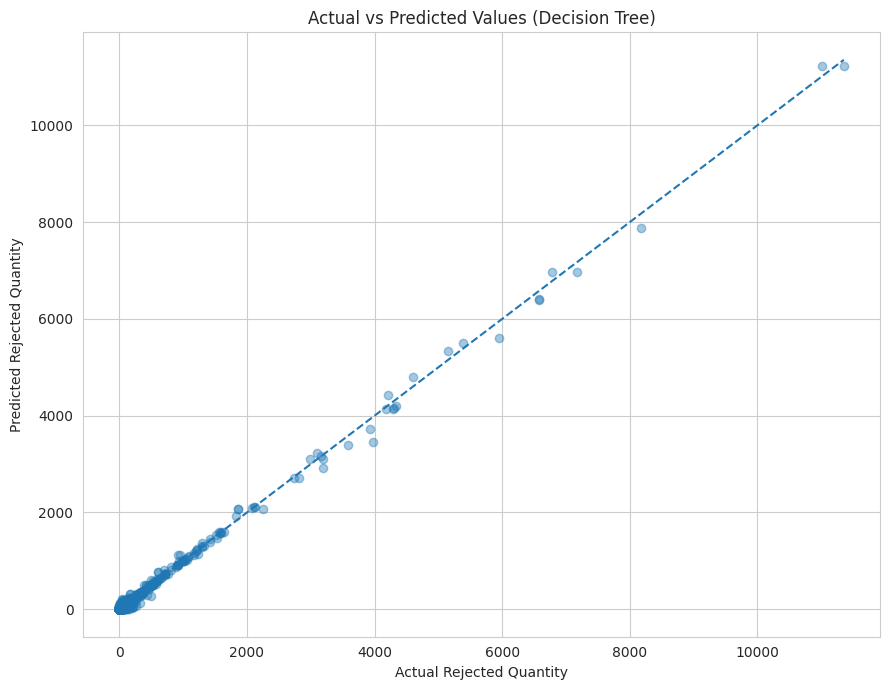

In [19]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.4
)

min_value = min(
    y_test.min(),
    best_predictions.min()
)

max_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.title(
    f"Actual vs Predicted Values ({best_model_name})"
)

plt.xlabel("Actual Rejected Quantity")
plt.ylabel("Predicted Rejected Quantity")

plt.tight_layout()
plt.show()

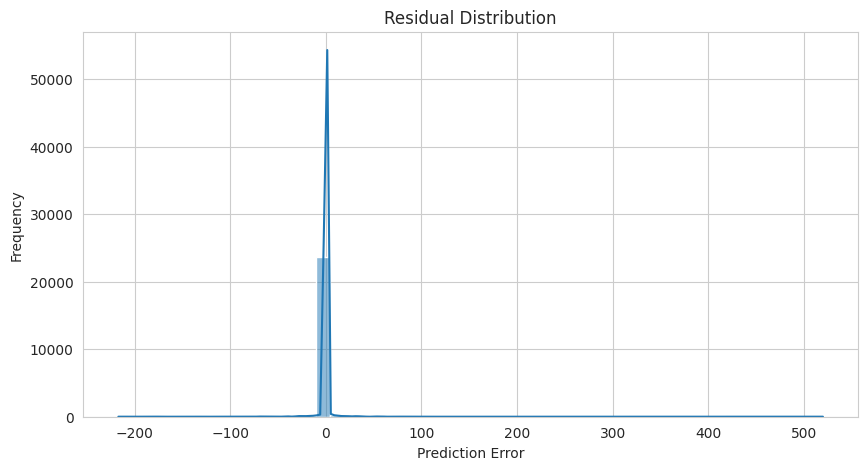

Mean Residual: 0.04539826661163846
Standard Deviation: 9.873858888595334


In [20]:
residuals = y_test - best_predictions

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

print("Mean Residual:", residuals.mean())

print("Standard Deviation:",
      residuals.std())

In [21]:
rf_model = trained_models['Random Forest']

feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features – Random Forest")

display(rf_importance.head(15))

Top 15 Important Features – Random Forest


,Feature,Importance
8,num__total_pdn_m_c,0.799803
9,num__total_pdn_per_order,0.061506
3,num__rec_beam_length_yds,0.043058
0,num__unnamed_0,0.031000
2,num__fabric_allowance,0.009074
1,num__req_finish_fabrics,0.007232
7,num__req_beam_length_yds,0.007005
21,cat__month_May,0.006458
6,num__req_grey_fabric,0.006289
19,cat__month_June,0.005410


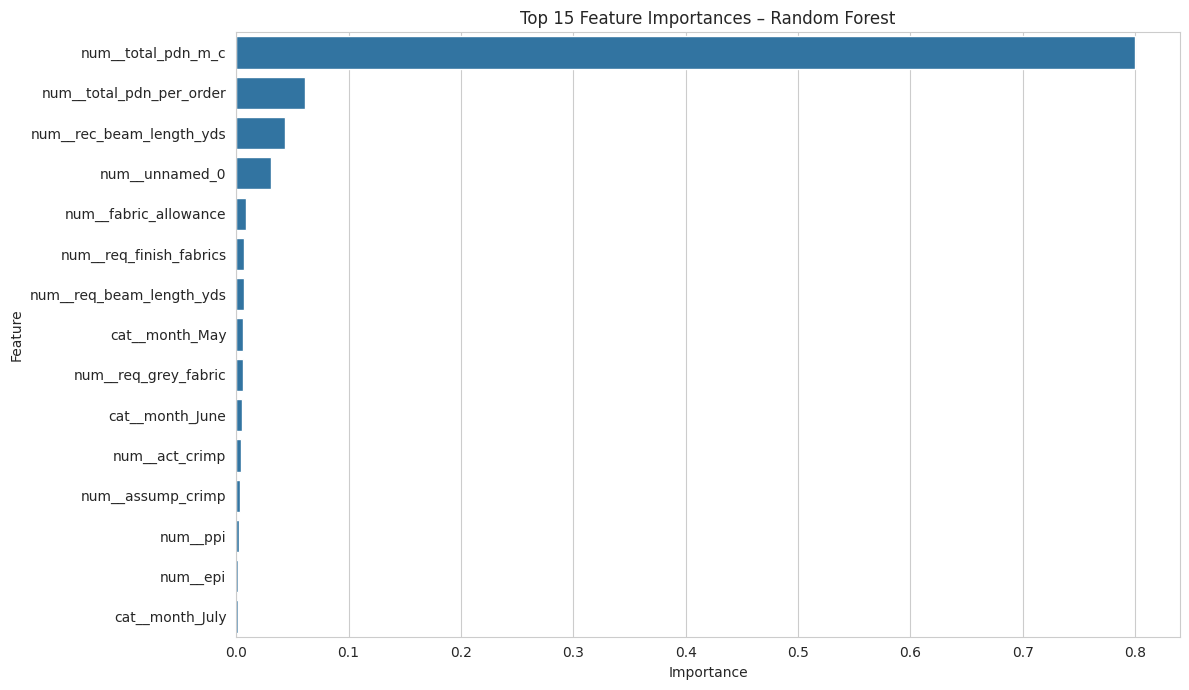

In [22]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=rf_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Feature Importances – Random Forest")

plt.tight_layout()
plt.show()

In [23]:
xgb_model = trained_models['XGBoost']

xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features – XGBoost")

display(xgb_importance.head(15))

Top 15 Important Features – XGBoost


,Feature,Importance
129,cat__construction_60x60/130x80,0.516457
51,cat__construction_40x40/100x76,0.166167
52,cat__construction_40x40/100x90,0.097643
9,num__total_pdn_per_order,0.061786
98,cat__construction_50x50/120x90,0.046525
8,num__total_pdn_m_c,0.039537
3,num__rec_beam_length_yds,0.015529
61,cat__construction_40x40/120x90,0.007039
2,num__fabric_allowance,0.005094
2216,cat__previous_pdn_infrequent_sklearn,0.003973


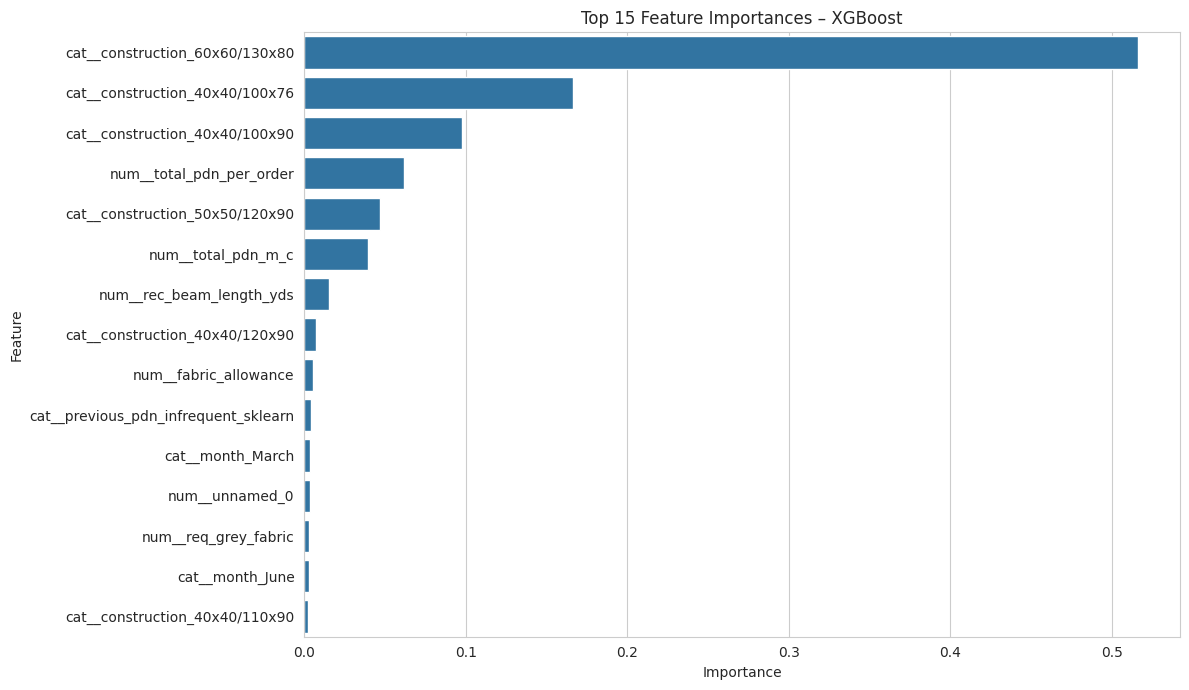

In [24]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=xgb_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Feature Importances – XGBoost")

plt.tight_layout()
plt.show()

In [25]:
# Select one test record as an example
sample_order = X_test.iloc[[0]]

actual_value = y_test.iloc[0]

predicted_value = xgb_model.predict(
    preprocessor.transform(sample_order)
)[0]

print("NEW PRODUCTION ORDER PREDICTION")

print("Actual Rejected Quantity:", actual_value)

print("Predicted Rejected Quantity:", predicted_value)

print("Prediction Error:",
      abs(actual_value - predicted_value))

NEW PRODUCTION ORDER PREDICTION
Actual Rejected Quantity: 0.0
Predicted Rejected Quantity: -0.15781537
Prediction Error: 0.1578153669834137


In [26]:
# Save comparative performance
results_df.to_csv(
    "model_performance_results.csv",
    index=False
)

# Save feature importance
xgb_importance.to_csv(
    "xgboost_feature_importance.csv",
    index=False
)

# Save actual vs predicted results
prediction_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': predictions['XGBoost']
})

prediction_df.to_csv(
    "actual_vs_predicted.csv",
    index=False
)

print("All result files saved successfully!")

All result files saved successfully!


In [1]:
from google.colab import files

files.download("model_performance_results.csv")
files.download("xgboost_feature_importance.csv")
files.download("actual_vs_predicted.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>